In [111]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [112]:
from dataclasses import replace
from pathlib import Path
import sys

import torch
from scipy.special import logit

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.config import DataConfig, AlgorithmConfig
from figures.experiments import (
    ExperimentConfig,
    run_statistical_experiment,
    plot_statistical_behavior,
)

torch.set_default_dtype(torch.float64)


In [138]:
config_balanced = ExperimentConfig(
    data=DataConfig(
        scale=1.0,
        label_prior=0.5,
        supervision_ratio=0.05,
        data_to_dimension_ratio=8.0,
        signal_law=lambda: torch.randn(1).item(),
    ),
    algorithm=AlgorithmConfig(
        n_iterations=400,
        positive_margin=logit(0.8),
        negative_margin=-logit(0.8),
        step_size=0.2,
        pseudo_label_param=2.0,
        penalty_param=0.1,
    ),
    d=5_000,
    seed=49,
)

results_balanced = run_statistical_experiment(config_balanced)

In [139]:
config_unbalanced = replace(
    config_balanced,
    data=replace(config_balanced.data, label_prior=0.2),
)

results_unbalanced = run_statistical_experiment(config_unbalanced)

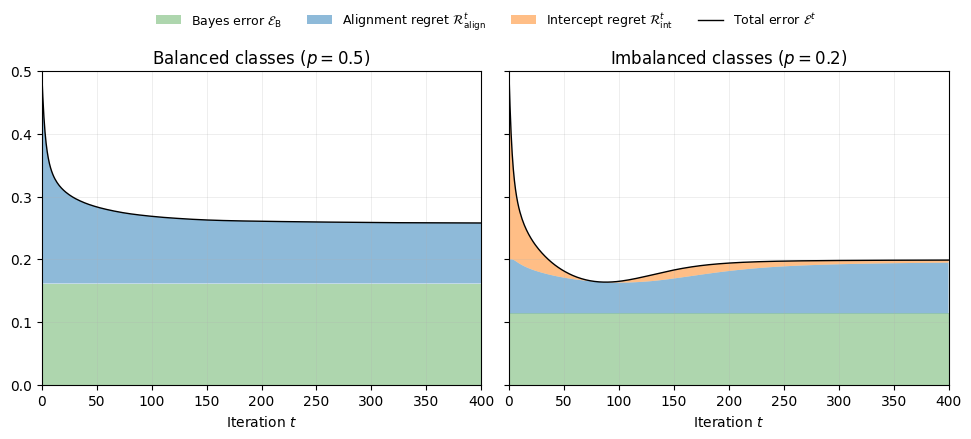

In [140]:
fig, axes = plot_statistical_behavior(
    [results_balanced, results_unbalanced],
    [
        rf"Balanced classes ($p={config_balanced.data.label_prior:g}$)",
        rf"Imbalanced classes ($p={config_unbalanced.data.label_prior:g}$)",
    ],
    save_image=True,
    image_path=project_root / "pdfs" / "statistical_behavior_comparison.png",
)

# Export vector artwork with fonts sized for the manuscript's full text width.
font_size = 8.0 * fig.get_figwidth() / 6.27
for ax in fig.axes:
    ax.title.set_fontsize(font_size)
    ax.xaxis.label.set_fontsize(font_size)
    ax.yaxis.label.set_fontsize(font_size)
    ax.tick_params(axis="both", labelsize=font_size)
for legend in fig.legends:
    for text in legend.get_texts():
        text.set_fontsize(font_size)
fig.savefig(
    project_root / "pdfs" / "statistical_behavior_comparison.pdf",
    bbox_inches="tight",
)
